In [36]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/processed/orders_validated.csv")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,LT Cluster,Cluster Min,Residual Days,Offset Step k,Candidate Ship Days (hypothesis),Order Key,Is Canada,Gap After Year Shift (days),Is Repeated Line,ID Prefix
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,...,A (~905),904,5,0,5,US-2021-103800,False,179,False,CHO
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,A (~905),904,5,0,5,US-2021-112326,False,179,False,CHO
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,A (~905),904,5,0,5,US-2021-112326,False,179,False,CHO
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,A (~905),904,5,0,5,US-2021-112326,False,179,False,CHO
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,A (~905),904,8,0,8,US-2021-141817,False,182,False,CHO


In [37]:
print("Order Date dtype:", df["Order Date"].dtype)
print("Ship Date dtype:", df["Ship Date"].dtype)

print("\nRaw date samples:")
print(df[["Order Date", "Ship Date"]].head())

print("\nMissing dates:")
print(df[["Order Date", "Ship Date"]].isna().sum())

# Test parsing independently
order_test = pd.to_datetime(
    df["Order Date"], format="%Y-%m-%d", errors="coerce"
)
ship_test = pd.to_datetime(
    df["Ship Date"], format="%Y-%m-%d", errors="coerce"
)

print("\nSuccessfully parsed Order Dates:", order_test.notna().sum())
print("Successfully parsed Ship Dates:", ship_test.notna().sum())

print("\nTest lead times:")
print((ship_test - order_test).dt.days.describe())

Order Date dtype: str
Ship Date dtype: str

Raw date samples:
   Order Date   Ship Date
0  2024-01-03  2026-06-30
1  2024-01-04  2026-07-01
2  2024-01-04  2026-07-01
3  2024-01-04  2026-07-01
4  2024-01-05  2026-07-05

Missing dates:
Order Date    0
Ship Date     0
dtype: int64

Successfully parsed Order Dates: 10194
Successfully parsed Ship Dates: 10194

Test lead times:
count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
dtype: float64


In [38]:
print("Dataset shape:", df.shape)

print("\nDate columns available:")
print([
    col for col in df.columns
    if "date" in col.lower() or "ship" in col.lower()
])

print("\nFirst 10 Order Dates:")
print(df["Order Date"].head(10))

print("\nFirst 10 Ship Dates:")
print(df["Ship Date"].head(10))

print("\nMissing values before date parsing:")
print(df[["Order Date", "Ship Date"]].isna().sum())

Dataset shape: (10194, 32)

Date columns available:
['Order Date', 'Ship Date', 'Ship Mode', 'Shipping Lead Time', 'Ship Year', 'Candidate Ship Days (hypothesis)']

First 10 Order Dates:
0    2024-01-03
1    2024-01-04
2    2024-01-04
3    2024-01-04
4    2024-01-05
5    2024-01-06
6    2024-01-06
7    2024-01-06
8    2024-01-06
9    2024-01-06
Name: Order Date, dtype: str

First 10 Ship Dates:
0    2026-06-30
1    2026-07-01
2    2026-07-01
3    2026-07-01
4    2026-07-05
5    2026-07-03
6    2026-07-03
7    2026-06-30
8    2026-07-03
9    2026-07-03
Name: Ship Date, dtype: str

Missing values before date parsing:
Order Date    0
Ship Date     0
dtype: int64


## Feature engineering: lead time

- **Shipping Lead Time** = Ship Date minus Order Date, in days, as supplied (raw).
- **Adjusted Lead Time** = same gap after moving Ship Date back by whole years (hypothesis, not confirmed). Compare differences only.

In [39]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

In [40]:

import pandas as pd
import numpy as np

# Reload the validated dataset to restore the original date strings
df = pd.read_csv("../data/processed/orders_validated.csv")

# Parse dates using the format confirmed in the CSV: YYYY-MM-DD
df["Order Date"] = pd.to_datetime(
    df["Order Date"], format="%Y-%m-%d", errors="coerce"
)
df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], format="%Y-%m-%d", errors="coerce"
)

print("Parsed Order Dates:", df["Order Date"].notna().sum())
print("Parsed Ship Dates:", df["Ship Date"].notna().sum())

# Calculate original shipping lead time
df["Shipping Lead Time"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

# Extract the year encoded in Order ID
df["Order ID Year"] = pd.to_numeric(
    df["Order ID"].astype(str).str.extract(
        r"^[A-Z]{2}-(\d{4})-"
    )[0],
    errors="coerce"
)

# Exploratory adjustment only; not a verified business rule
YEAR_SHIFT = {2021: 2, 2022: 3, 2023: 3, 2024: 4}

shifted_ship = pd.Series(
    pd.NaT, index=df.index, dtype="datetime64[ns]"
)

for year, shift in YEAR_SHIFT.items():
    mask = (
        df["Order ID Year"].eq(year)
        & df["Ship Date"].notna()
    )
    shifted_ship.loc[mask] = (
        df.loc[mask, "Ship Date"] - pd.DateOffset(years=shift)
    )

df["Adjusted Lead Time"] = (
    shifted_ship - df["Order Date"]
).dt.days

# Summaries and diagnostics
print("\nLead-time summary:")
display(
    df[["Shipping Lead Time", "Adjusted Lead Time"]]
    .describe()
    .round(2)
)

print("\nMean lead time by ship mode:")
display(
    df.groupby("Ship Mode")[
        ["Shipping Lead Time", "Adjusted Lead Time"]
    ].mean().round(2)
)


Parsed Order Dates: 10194
Parsed Ship Dates: 10194

Lead-time summary:


,Shipping Lead Time,Adjusted Lead Time
count,10194.00,10194.00
mean,1320.84,177.59
std,262.44,1.82
min,904.00,173.00
25%,1271.00,176.00
50%,1274.00,178.00
75%,1638.00,179.00
max,1642.00,185.00



Mean lead time by ship mode:


,Shipping Lead Time,Adjusted Lead Time
Ship Mode,,
First Class,1338.28,175.84
Same Day,1333.44,173.63
Second Class,1323.85,176.86
Standard Class,1314.33,178.63


In [41]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Cluster Min,Residual Days,Offset Step k,Candidate Ship Days (hypothesis),Order Key,Is Canada,Gap After Year Shift (days),Is Repeated Line,ID Prefix,Adjusted Lead Time
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,...,904,5,0,5,US-2021-103800,False,179,False,CHO,179
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,904,5,0,5,US-2021-112326,False,179,False,CHO,179
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,904,5,0,5,US-2021-112326,False,179,False,CHO,179
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,904,5,0,5,US-2021-112326,False,179,False,CHO,179
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,904,8,0,8,US-2021-141817,False,182,False,CHO,182


### Result: lead time columns

- Date columns converted to real dates (`datetime64`) with explicit formats.
- **Shipping Lead Time** = Ship Date minus Order Date, in days, as supplied: 904 to 1,642 days (mean about 1,320.8). Not real shipping time.
- **Adjusted Lead Time** = same gap after moving Ship Date back by whole years (2, 3, 3, 4 years for Order ID years 2021 to 2024): 173 to 185 days (mean about 177.6).
- Adjusted means sort by ship mode: Same Day (about 173.6), First Class (about 175.8), Second Class (about 176.9), Standard (about 178.6).

**Status:** The adjustment is a hypothesis fitted to this data, not a confirmed rule. Compare differences only, not exact days. Nothing is saved yet; both columns live in `df` until the final save.

In [42]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Cluster Min,Residual Days,Offset Step k,Candidate Ship Days (hypothesis),Order Key,Is Canada,Gap After Year Shift (days),Is Repeated Line,ID Prefix,Adjusted Lead Time
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,...,904,5,0,5,US-2021-103800,False,179,False,CHO,179
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,904,5,0,5,US-2021-112326,False,179,False,CHO,179
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,904,5,0,5,US-2021-112326,False,179,False,CHO,179
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,904,5,0,5,US-2021-112326,False,179,False,CHO,179
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,904,8,0,8,US-2021-141817,False,182,False,CHO,182


In [43]:

# Check the unique products in our dataset
print("Number of unique products:", df["Product Name"].nunique())

display(
    df[["Product Name", "Division"]]
    .drop_duplicates()
    .sort_values("Product Name")
    .reset_index(drop=True)
)


Number of unique products: 15


,Product Name,Division
0,Everlasting Gobstopper,Sugar
1,Fizzy Lifting Drinks,Sugar
2,Fun Dip,Sugar
3,Hair Toffee,Sugar
4,Kazookles,Other
5,Laffy Taffy,Sugar
6,Lickable Wallpaper,Other
7,Nerds,Sugar
8,SweeTARTS,Sugar
9,Wonka Bar - Fudge Mallows,Chocolate


In [44]:

# Map each product to its factory
product_factory_mapping = {
    "Wonka Bar - Nutty Crunch Surprise": "Lot's O' Nuts",
    "Wonka Bar - Fudge Mallows": "Lot's O' Nuts",
    "Wonka Bar -Scrumdiddlyumptious": "Lot's O' Nuts",
    "Wonka Bar - Milk Chocolate": "Wicked Choccy's",
    "Wonka Bar - Triple Dazzle Caramel": "Wicked Choccy's",
    "Laffy Taffy": "Sugar Shack",
    "SweeTARTS": "Sugar Shack",
    "Nerds": "Sugar Shack",
    "Fun Dip": "Sugar Shack",
    "Fizzy Lifting Drinks": "Sugar Shack",
    "Everlasting Gobstopper": "Secret Factory",
    "Hair Toffee": "The Other Factory",
    "Lickable Wallpaper": "Secret Factory",
    "Wonka Gum": "Secret Factory",
    "Kazookles": "The Other Factory"
}

# Check mapping coverage before modifying df
unmapped_products = set(df["Product Name"].unique()) - set(product_factory_mapping.keys())

print("Products in dataset:", df["Product Name"].nunique())
print("Products in mapping:", len(product_factory_mapping))
print("Unmapped products:", unmapped_products)


Products in dataset: 15
Products in mapping: 15
Unmapped products: set()


In [45]:

df["Factory"] = df["Product Name"].map(product_factory_mapping)

print("Missing factory assignments:", df["Factory"].isna().sum())

print("\nOrders by factory:")
display(df["Factory"].value_counts().rename_axis("Factory").reset_index(name="Order Lines"))


Missing factory assignments: 0

Orders by factory:


,Factory,Order Lines
0,Lot's O' Nuts,5692
1,Wicked Choccy's,4152
2,Secret Factory,217
3,The Other Factory,100
4,Sugar Shack,33


In [46]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Residual Days,Offset Step k,Candidate Ship Days (hypothesis),Order Key,Is Canada,Gap After Year Shift (days),Is Repeated Line,ID Prefix,Adjusted Lead Time,Factory
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,...,5,0,5,US-2021-103800,False,179,False,CHO,179,Wicked Choccy's
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,5,0,5,US-2021-112326,False,179,False,CHO,179,Wicked Choccy's
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,5,0,5,US-2021-112326,False,179,False,CHO,179,Lot's O' Nuts
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,5,0,5,US-2021-112326,False,179,False,CHO,179,Lot's O' Nuts
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,8,0,8,US-2021-141817,False,182,False,CHO,182,Wicked Choccy's


In [47]:

# Factory locations: latitude and longitude
factory_coordinates = {
    "Lot's O' Nuts": (32.881893, -111.768036),
    "Wicked Choccy's": (32.076176, -81.088371),
    "Sugar Shack": (48.119140, -96.181150),
    "Secret Factory": (41.446333, -90.565487),
    "The Other Factory": (35.117500, -89.971107)
}

# Verify all factories in the dataset have coordinates
factories_in_data = set(df["Factory"].dropna().unique())
factories_with_coordinates = set(factory_coordinates.keys())

print("Factories in dataset:", len(factories_in_data))
print("Factories with coordinates:", len(factories_with_coordinates))
print("Factories without coordinates:", factories_in_data - factories_with_coordinates)


Factories in dataset: 5
Factories with coordinates: 5
Factories without coordinates: set()


In [48]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Residual Days,Offset Step k,Candidate Ship Days (hypothesis),Order Key,Is Canada,Gap After Year Shift (days),Is Repeated Line,ID Prefix,Adjusted Lead Time,Factory
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,...,5,0,5,US-2021-103800,False,179,False,CHO,179,Wicked Choccy's
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,5,0,5,US-2021-112326,False,179,False,CHO,179,Wicked Choccy's
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,5,0,5,US-2021-112326,False,179,False,CHO,179,Lot's O' Nuts
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,5,0,5,US-2021-112326,False,179,False,CHO,179,Lot's O' Nuts
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,8,0,8,US-2021-141817,False,182,False,CHO,182,Wicked Choccy's


In [49]:

df["Factory Latitude"] = df["Factory"].map(
    lambda factory: factory_coordinates[factory][0]
)

df["Factory Longitude"] = df["Factory"].map(
    lambda factory: factory_coordinates[factory][1]
)

print("Missing factory latitudes:", df["Factory Latitude"].isna().sum())
print("Missing factory longitudes:", df["Factory Longitude"].isna().sum())

display(
    df[["Product Name", "Factory", "Factory Latitude", "Factory Longitude"]]
    .drop_duplicates()
    .sort_values("Factory")
    .reset_index(drop=True)
)


Missing factory latitudes: 0
Missing factory longitudes: 0


,Product Name,Factory,Factory Latitude,Factory Longitude
0,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,32.881893,-111.768036
1,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,32.881893,-111.768036
2,Wonka Bar - Fudge Mallows,Lot's O' Nuts,32.881893,-111.768036
3,Wonka Gum,Secret Factory,41.446333,-90.565487
4,Lickable Wallpaper,Secret Factory,41.446333,-90.565487
5,Everlasting Gobstopper,Secret Factory,41.446333,-90.565487
6,Fizzy Lifting Drinks,Sugar Shack,48.119140,-96.181150
7,Laffy Taffy,Sugar Shack,48.119140,-96.181150
8,SweeTARTS,Sugar Shack,48.119140,-96.181150
9,Nerds,Sugar Shack,48.119140,-96.181150


In [50]:
df["Factory"] = df["Product Name"].map(product_factory_mapping)

print("Missing factory assignments:", df["Factory"].isna().sum())

print("\nOrder lines by factory:")
display(
    df["Factory"]
    .value_counts()
    .rename_axis("Factory")
    .reset_index(name="Order_Lines")
)

print("\nUnique orders:", df["Order Key"].nunique())

shipment_count = (
    df[["Order Key", "Factory"]]
    .dropna()
    .drop_duplicates()
    .shape[0]
)

print("Unique order-factory shipments:", shipment_count)

Missing factory assignments: 0

Order lines by factory:


,Factory,Order_Lines
0,Lot's O' Nuts,5692
1,Wicked Choccy's,4152
2,Secret Factory,217
3,The Other Factory,100
4,Sugar Shack,33



Unique orders: 5111
Unique order-factory shipments: 6958


In [12]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Candidate Ship Days (hypothesis),Order Key,Is Canada,Gap After Year Shift (days),Is Repeated Line,ID Prefix,Adjusted Lead Time,Factory,Factory Latitude,Factory Longitude
0,1,US-2021-103800-CHO-MIL-31000,NaT,NaT,Standard Class,103800,United States,Houston,Texas,77095,...,5,US-2021-103800,False,179,False,CHO,NaN,Wicked Choccy's,32.076176,-81.088371
1,2,US-2021-112326-CHO-TRI-54000,NaT,NaT,Standard Class,112326,United States,Naperville,Illinois,60540,...,5,US-2021-112326,False,179,False,CHO,NaN,Wicked Choccy's,32.076176,-81.088371
2,3,US-2021-112326-CHO-NUT-13000,NaT,NaT,Standard Class,112326,United States,Naperville,Illinois,60540,...,5,US-2021-112326,False,179,False,CHO,NaN,Lot's O' Nuts,32.881893,-111.768036
3,4,US-2021-112326-CHO-SCR-58000,NaT,NaT,Standard Class,112326,United States,Naperville,Illinois,60540,...,5,US-2021-112326,False,179,False,CHO,NaN,Lot's O' Nuts,32.881893,-111.768036
4,5,US-2021-141817-CHO-TRI-54000,NaT,NaT,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,8,US-2021-141817,False,182,False,CHO,NaN,Wicked Choccy's,32.076176,-81.088371


In [51]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Country/Region', 'City', 'State/Province',
       'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name',
       'Sales', 'Units', 'Gross Profit', 'Cost', 'Shipping Lead Time',
       'Order ID Year', 'Order Year', 'Ship Year', 'LT Cluster', 'Cluster Min',
       'Residual Days', 'Offset Step k', 'Candidate Ship Days (hypothesis)',
       'Order Key', 'Is Canada', 'Gap After Year Shift (days)',
       'Is Repeated Line', 'ID Prefix', 'Adjusted Lead Time', 'Factory',
       'Factory Latitude', 'Factory Longitude'],
      dtype='str')

In [52]:
df['Region'].unique()

<ArrowStringArray>
['Interior', 'Atlantic', 'Gulf', 'Pacific']
Length: 4, dtype: str

In [53]:
factory_region_summary = (
    df.groupby(["Factory", "Region"])
    .agg(
        Unique_Orders=("Order Key", "nunique"),
        Order_Lines=("Order Key", "size")
    )
    .reset_index()
)

region_order_matrix = factory_region_summary.pivot(
    index="Factory",
    columns="Region",
    values="Unique_Orders"
).fillna(0).astype(int)

display(region_order_matrix)

Region,Atlantic,Gulf,Interior,Pacific
Factory,,,,
Lot's O' Nuts,1062,576,854,1160
Secret Factory,69,35,44,63
Sugar Shack,18,3,8,3
The Other Factory,37,19,11,31
Wicked Choccy's,850,467,689,959


## Route Categorization

To analyze distribution patterns across the supply network, routes are categorized hierarchically by **Factory → Customer Country → Customer Region → Customer State/Province**. The dataset is first divided into US and Canadian customer orders, allowing the distribution patterns in each country to be examined separately.

### 1. Factory → Customer Region

For the United States and Canada separately, orders are grouped by factory and customer region. Heatmaps visualize the number of unique orders associated with each factory-region combination, helping identify regional concentrations and understand how order volumes are distributed across the regions served by each factory.

### 2. Factory → Customer State/Province

Within each country, the analysis is further refined from region to individual state or province. Orders are grouped by factory, customer region, and state/province to identify specific destinations receiving the most orders and compare distribution patterns at a more granular geographic level.

This hierarchical approach provides a structured view of the distribution network, moving from country-level separation to regional analysis and finally to state/province-level detail.

In [54]:

# Level 1: Factory → Country

factory_country_summary = (
    df.groupby(["Factory", "Country/Region"])
    .agg(
        Unique_Orders=("Order Key", "nunique"),
        Order_Lines=("Order Key", "size")
    )
    .reset_index()
    .sort_values(["Factory", "Country/Region"])
)

display(factory_country_summary)


,Factory,Country/Region,Unique_Orders,Order_Lines
0,Lot's O' Nuts,Canada,72,104
1,Lot's O' Nuts,United States,3580,5588
2,Secret Factory,Canada,4,4
3,Secret Factory,United States,207,213
4,Sugar Shack,United States,32,33
5,The Other Factory,United States,98,100
6,Wicked Choccy's,Canada,57,92
7,Wicked Choccy's,United States,2908,4060


In [55]:
# Separate US and Canadian customer orders
df_us = df[
    df["Country/Region"].isin(["United States", "United States of America", "US"])
].copy()

df_canada = df[
    df["Country/Region"].isin(["Canada"])
].copy()

print("US records:", len(df_us))
print("Canada records:", len(df_canada))
print("Total records:", len(df))

# Verify that no records were excluded
assert len(df_us) + len(df_canada) == len(df), "Check country names!"

US records: 9994
Canada records: 200
Total records: 10194


In [56]:
df_canada['Region'].unique()

<ArrowStringArray>
['Atlantic', 'Pacific', 'Interior']
Length: 3, dtype: str

In [57]:
df_us['Region'].unique()

<ArrowStringArray>
['Interior', 'Atlantic', 'Gulf', 'Pacific']
Length: 4, dtype: str

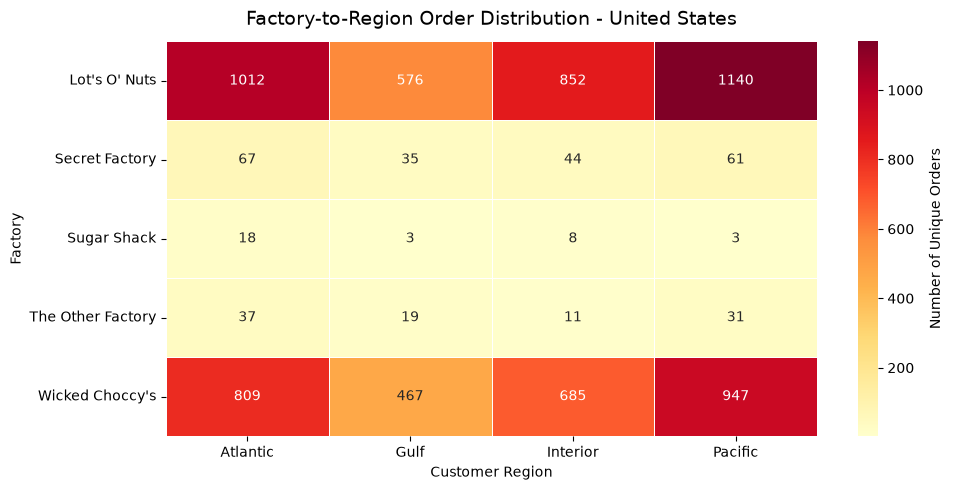

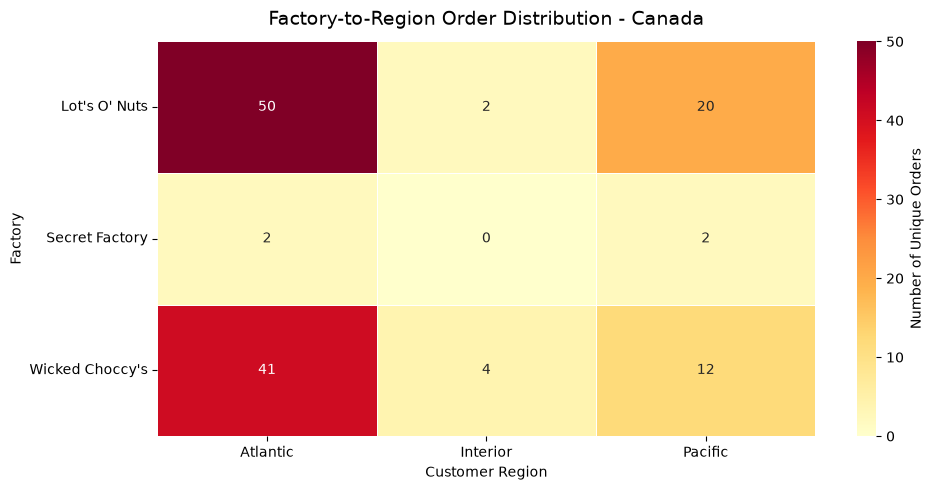

In [58]:

import matplotlib.pyplot as plt
import seaborn as sns

def plot_factory_region_heatmap(data, country):
    # Count unique orders for each factory-region combination
    region_matrix = (
        data.groupby(["Factory", "Region"])["Order Key"]
        .nunique()
        .unstack(fill_value=0)
    )

    # Plot heatmap
    plt.figure(figsize=(10, 5))

    sns.heatmap(
        region_matrix,
        annot=True,
        fmt="d",
        cmap="YlOrRd",
        linewidths=0.5,
        cbar_kws={"label": "Number of Unique Orders"}
    )

    plt.title(
        f"Factory-to-Region Order Distribution - {country}",
        fontsize=14,
        pad=12
    )
    plt.xlabel("Customer Region")
    plt.ylabel("Factory")
    plt.xticks(rotation=0)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


# Generate the two heatmaps
plot_factory_region_heatmap(df_us, "United States")
plot_factory_region_heatmap(df_canada, "Canada")


In [59]:

# Level 3: Factory → Country → Region → State/Province

factory_state_summary = (
    df.groupby(
        ["Country/Region", "Region", "State/Province", "Factory"],
        dropna=False
    )
    .agg(
        Unique_Orders=("Order Key", "nunique"),
        Order_Lines=("Order Key", "size")
    )
    .reset_index()
    .sort_values(
        ["Country/Region", "Region", "State/Province", "Factory"]
    )
)

display(factory_state_summary.head(30))


,Country/Region,Region,State/Province,Factory,Unique_Orders,Order_Lines
0,Canada,Atlantic,New Brunswick,Lot's O' Nuts,4,4
1,Canada,Atlantic,New Brunswick,Wicked Choccy's,4,4
2,Canada,Atlantic,Newfoundland and Labrador,Lot's O' Nuts,5,6
3,Canada,Atlantic,Nova Scotia,Wicked Choccy's,6,6
4,Canada,Atlantic,Ontario,Lot's O' Nuts,17,28
5,Canada,Atlantic,Ontario,Wicked Choccy's,13,30
6,Canada,Atlantic,Prince Edward Island,Lot's O' Nuts,4,6
7,Canada,Atlantic,Prince Edward Island,Wicked Choccy's,2,4
8,Canada,Atlantic,Quebec,Lot's O' Nuts,20,24
9,Canada,Atlantic,Quebec,Secret Factory,2,2


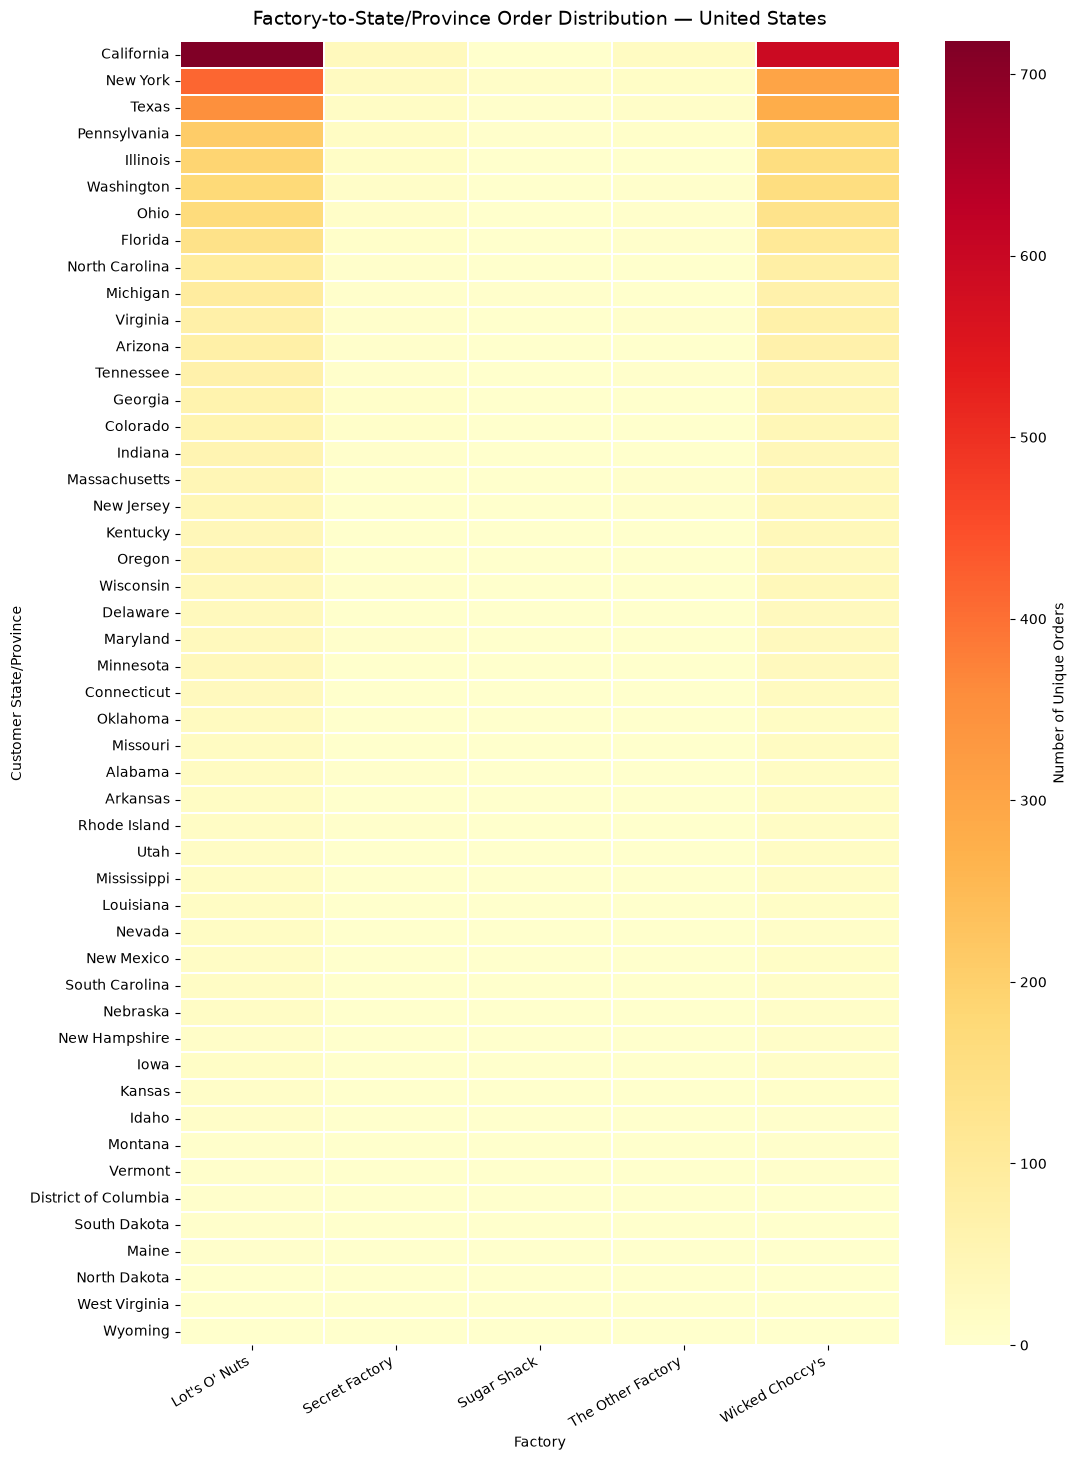

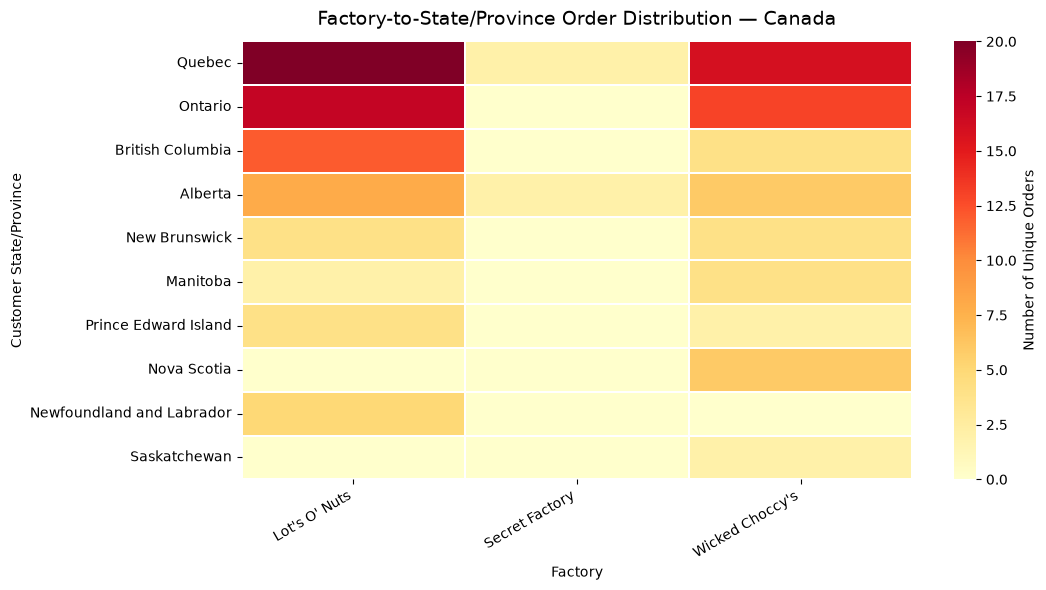

In [60]:

import matplotlib.pyplot as plt
import seaborn as sns

def plot_factory_state_heatmap(data, country):
    # Count unique orders by state/province and factory
    state_matrix = (
        data.groupby(["State/Province", "Factory"])["Order Key"]
        .nunique()
        .unstack(fill_value=0)
    )

    # Sort destinations by total order count
    state_matrix = state_matrix.loc[
        state_matrix.sum(axis=1).sort_values(ascending=False).index
    ]

    plt.figure(figsize=(11, max(6, len(state_matrix) * 0.3)))

    sns.heatmap(
        state_matrix,
        cmap="YlOrRd",
        annot=False,
        linewidths=0.3,
        cbar_kws={"label": "Number of Unique Orders"}
    )

    plt.title(
        f"Factory-to-State/Province Order Distribution — {country}",
        fontsize=14,
        pad=12
    )
    plt.xlabel("Factory")
    plt.ylabel("Customer State/Province")
    plt.xticks(rotation=30, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


# Generate state/province heatmaps
plot_factory_state_heatmap(df_us, "United States")
plot_factory_state_heatmap(df_canada, "Canada")


In [61]:

# Group shipment records by shipping mode
ship_mode_summary = (
    df.groupby("Ship Mode")
    .agg(
        Order_Lines=("Order Key", "size"),
        Unique_Orders=("Order Key", "nunique"),
        Average_Lead_Time=("Shipping Lead Time", "mean"),
        Median_Lead_Time=("Shipping Lead Time", "median")
    )
    .reset_index()
    .sort_values("Unique_Orders", ascending=False)
)

display(ship_mode_summary.round(2))


,Ship Mode,Order_Lines,Unique_Orders,Average_Lead_Time,Median_Lead_Time
3,Standard Class,6120,3068,1314.33,1274.0
2,Second Class,1979,982,1323.85,1273.0
0,First Class,1548,795,1338.28,1272.0
1,Same Day,547,266,1333.44,1269.0


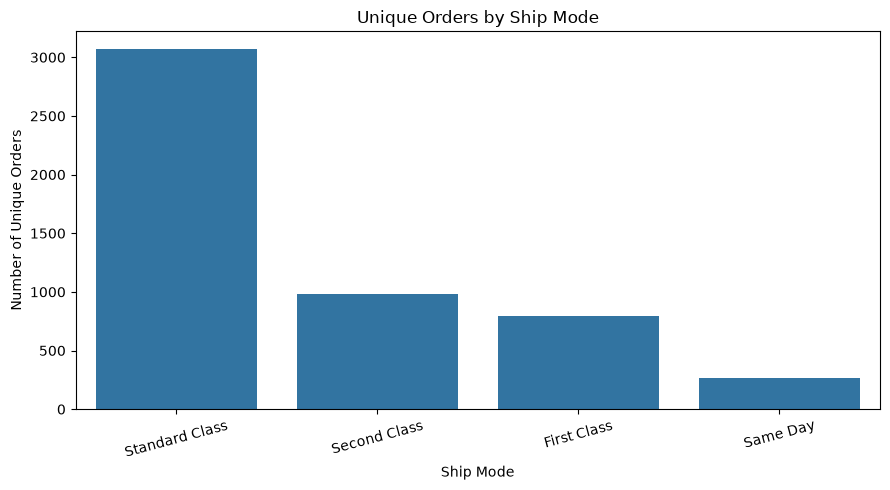

In [62]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=ship_mode_summary,
    x="Ship Mode",
    y="Unique_Orders"
)

plt.title("Unique Orders by Ship Mode")
plt.xlabel("Ship Mode")
plt.ylabel("Number of Unique Orders")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [63]:
df.to_csv("../data/processed/orders_prepared.csv", index=False)
print("Prepared dataset saved successfully.")

Prepared dataset saved successfully.
